# Validation visuelle des détecteurs de patterns

Charge l'historique OHLCV d'un titre (depuis la base, si l'environnement Docker de la Phase 0 est démarré et peuplé — voir le README racine), exécute `engine.detect.detect_all`, et affiche le graphique en chandeliers avec la figure détectée surlignée (mplfinance).

Si la base n'est pas accessible (ou ne contient pas encore d'historique pour le titre demandé), le notebook retombe automatiquement sur une série synthétique de démonstration (un Double Bottom construit exactement comme dans `tests/test_patterns.py`), pour rester exécutable sans aucune infrastructure.

In [1]:
import numpy as np
import pandas as pd
import mplfinance as mpf

from engine.detect import detect_all

In [2]:
def ramp(start, end, n):
    return list(np.linspace(start, end, n))


def path(*segments):
    """Concatène des segments en supprimant le premier point de chaque
    segment après le premier (identique au dernier point du précédent)."""
    result = list(segments[0])
    for seg in segments[1:]:
        result.extend(seg[1:])
    return result


def make_demo_df():
    """Un Double Bottom synthétique (même construction que
    tests/test_patterns.py::TestDoubleBottom) : deux creux à niveau
    comparable, séparés par un pic de résistance, confirmé par une cassure
    au-dessus de ce pic sur la dernière séance."""
    closes = path(ramp(100, 90, 7), ramp(90, 100, 9), ramp(100, 90.5, 9), ramp(90.5, 103, 9))
    idx = pd.bdate_range(start="2023-01-02", periods=len(closes))
    close = pd.Series(closes, index=idx, dtype=float)
    open_ = close.shift(1).fillna(close.iloc[0])
    high = pd.concat([open_, close], axis=1).max(axis=1) * 1.004
    low = pd.concat([open_, close], axis=1).min(axis=1) * 0.996
    volume = pd.Series(1_000_000, index=idx, dtype="int64")
    return pd.DataFrame({"open": open_, "high": high, "low": low, "close": close, "volume": volume})


def load_symbol_or_demo(symbol: str):
    """Essaie de charger l'historique réel de `symbol` depuis la base
    (Phase 0 + `python -m ingestion.ohlcv` déjà exécutés) ; retombe sur les
    données de démonstration si la base est inaccessible ou vide."""
    try:
        from engine.run_detection import load_prices
        from ingestion.db import get_engine

        df = load_prices(get_engine(), symbol)
        if not df.empty:
            return df, "base de données"
    except Exception as exc:
        print(f"Base de données indisponible ({exc!r}) — utilisation des données de démonstration.")
    return make_demo_df(), "démonstration (synthétique)"


SYMBOL = "AIR.PA"
df, source = load_symbol_or_demo(SYMBOL)
print(f"Source des données : {source} ({len(df)} séances)")
df.tail()

Base de données indisponible (OperationalError("(psycopg.errors.ConnectionTimeout) connection timeout expired\nMultiple connection attempts failed. All failures were:\n- host: 'localhost', port: 5432, hostaddr: '::1': connection timeout expired\n- host: 'localhost', port: 5432, hostaddr: '127.0.0.1': connection timeout expired")) — utilisation des données de démonstration.
Source des données : démonstration (synthétique) (31 séances)


,open,high,low,close,volume
2023-02-07,95.1875,97.13700,94.80675,96.7500,1000000
2023-02-08,96.7500,98.70575,96.36300,98.3125,1000000
2023-02-09,98.3125,100.27450,97.91925,99.8750,1000000
2023-02-10,99.8750,101.84325,99.47550,101.4375,1000000
2023-02-13,101.4375,103.41200,101.03175,103.0000,1000000


In [3]:
matches = detect_all(df)
for m in matches:
    print(f"{m.pattern_type:28s} confiance={m.confidence:5.1f}  détecté le {m.detected_at.date()}")
if not matches:
    print("Aucune figure détectée sur cette série.")

Double Bottom                confiance= 65.0  détecté le 2023-02-13


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


... (15 outputs left out)

findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight semibold, now using 700.


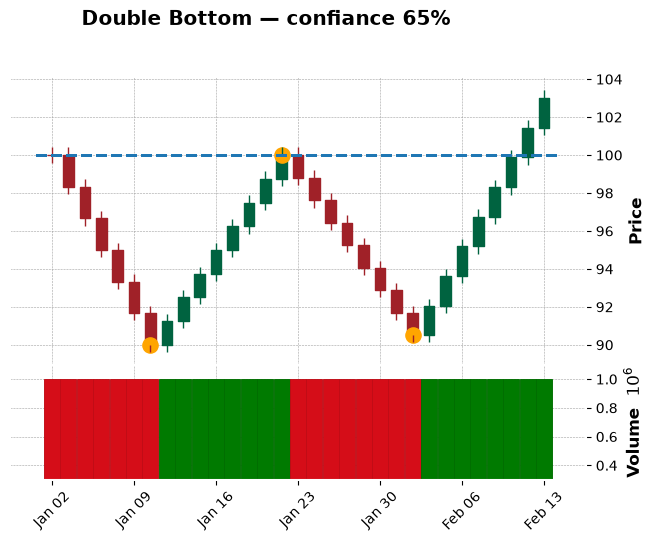

In [4]:
LEVEL_KEYS = {"resistance", "support"}


def plot_match(df, match, title=None):
    """Surligne les points clés et niveaux de la figure détectée sur un
    graphique en chandeliers. Générique sur la forme du `context` de chaque
    détecteur (voir engine/patterns/*.py) : les points {index, price} sont
    marqués, les niveaux nommés resistance/support/neckline sont tracés en
    ligne horizontale."""
    markers, hlines = [], []
    for key, value in match.context.items():
        if isinstance(value, dict) and "price" in value:
            price = value["price"]
            if "index" in value:
                markers.append((value["index"], price))
            if "points" in value:
                markers.extend((i, price) for i in value["points"])
            if "points" in value or key in LEVEL_KEYS:
                hlines.append(price)
        elif key in LEVEL_KEYS and isinstance(value, (int, float)):
            hlines.append(float(value))

    plot_kwargs = dict(
        type="candle",
        style="charles",
        volume=True,
        title=title or f"{match.pattern_type} — confiance {match.confidence:.0f}%",
    )

    if markers:
        marker_series = pd.Series(np.nan, index=df.index)
        for pos, price in markers:
            marker_series.iloc[pos] = price
        plot_kwargs["addplot"] = [
            mpf.make_addplot(marker_series, type="scatter", markersize=120, marker="o", color="orange")
        ]
    # mplfinance rejette hlines=None : la clé doit être absente plutôt que
    # valoir None quand il n'y a aucun niveau à tracer.
    if hlines:
        plot_kwargs["hlines"] = dict(hlines=hlines, colors=["tab:blue"] * len(hlines), linestyle="--")

    mpf.plot(df, **plot_kwargs)


if matches:
    plot_match(df, matches[0])
else:
    mpf.plot(df, type="candle", style="charles", volume=True, title=f"{SYMBOL} — aucune figure détectée")

**Notes** :
- Changer `SYMBOL` pour valider un autre titre de l'univers une fois la base peuplée (`python -m ingestion.ohlcv` puis relancer ce notebook).
- Les scores de confiance viennent de l'heuristique v1 (`engine/confidence.py`) : géométrie + confirmation de volume + alignement de tendance. Ils seront remplacés par un modèle appris en Phase 2 — voir `George_Prompts_Claude_Code.md`.